# 06_eda - exploratory analysis on the full published data (run by hand after a successful job run)

**No sampling:** every number and plot below is an aggregate over the full published silver table
(all accepted November 2019 events) or the full feature table. Only small aggregated results are brought to the driver.
Results are also saved to `curated/project/eda/eda_summary.json`. Export this notebook as HTML (with outputs) for the evidence.

In [0]:
dbutils.widgets.removeAll()

In [0]:
dbutils.widgets.text("lake", "amazonlake60304642")
dbutils.widgets.text("schema", "s_60304642")
dbutils.widgets.text("catalog", "dsai3202_databricks")
dbutils.widgets.text("source_container", "processed")

In [0]:
%run ./00_common

# 00_common - shared settings, paths and helpers
Every task notebook starts with `%run ./00_common`. Nothing here writes data.

| Job parameter | Meaning |
|---|---|
| `lake` | Lab-3 storage account, e.g. `amazonlake60304642` |
| `catalog`, `schema` | Unity Catalog names from Lab-5/6 |
| `run_id` | `{{job.run_id}}` in the job; a manual id when run by hand |
| `input` | `full` = the preserved raw file, `test_bad` = the separate corrupted test input |
| `source_container` | `raw` (default) or `processed` if Databricks cannot read raw (landing copy) |
| `compare_to` | a successful run id; the run then proves SAME CONTENT against it |

Adapted from DSAI3202 Lab-5 (validation, balanced counts, Delta) and Lab-6 (prepare -> validate -> publish, run folders, gate).

{
  "lake": "amazonlake60304642",
  "catalog": "dsai3202_databricks",
  "schema": "s_60304642",
  "run_id": "manual-20261114T133415Z",
  "input": "full",
  "source_container": "processed",
  "compare_to": "",
  "silver_table": "dsai3202_databricks.s_60304642.project_silver_events",
  "features_table": "dsai3202_databricks.s_60304642.project_features_v1"
}


/home/spark-6c4f4597-ec1b-4e04-a760-99/.ipykernel/23554/command-5296352083289421-820008573:15: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  P["run_id"] = "manual-" + datetime.datetime.utcnow().strftime("%Y%m%dT%H%M%SZ")


In [0]:
import matplotlib.pyplot as plt
latest = read_json(LATEST)
silver = table_version(SILVER_TABLE, latest["silver_version"])
feat = table_version(FEATURES_TABLE, latest["features_version"])
print("silver version", latest["silver_version"], "| features version", latest["features_version"], "| run", latest["run_id"])
S = {"run_id": latest["run_id"], "silver_version": latest["silver_version"], "features_version": latest["features_version"]}

silver version 29 | features version 5 | run 926454798811512


## 1. Population counts

In [0]:
pop = silver.agg(F.count(F.lit(1)).alias("events"), F.countDistinct("user_id").alias("users"),
                 F.countDistinct("user_session").alias("sessions"), F.countDistinct("product_id").alias("products"),
                 F.countDistinct("category_l1").alias("top_categories"), F.countDistinct("brand").alias("brands")).first().asDict()
by_type = {r["event_type"]: r["count"] for r in silver.groupBy("event_type").count().collect()}
S["population"] = {**pop, "by_event_type": by_type}
print(json.dumps(S["population"], indent=2))

{
  "events": 67401450,
  "users": 3696117,
  "sessions": 13776050,
  "products": 190662,
  "top_categories": 14,
  "brands": 4201,
  "by_event_type": {
    "purchase": 916930,
    "view": 63554512,
    "cart": 2930008
  }
}


## 2. Events per day (look for sale days such as 15-17 and 29 November)

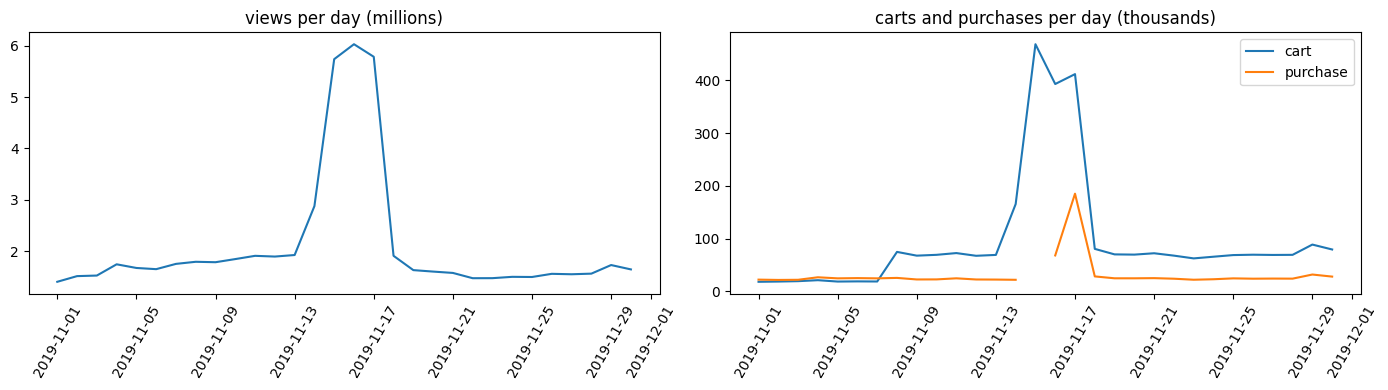

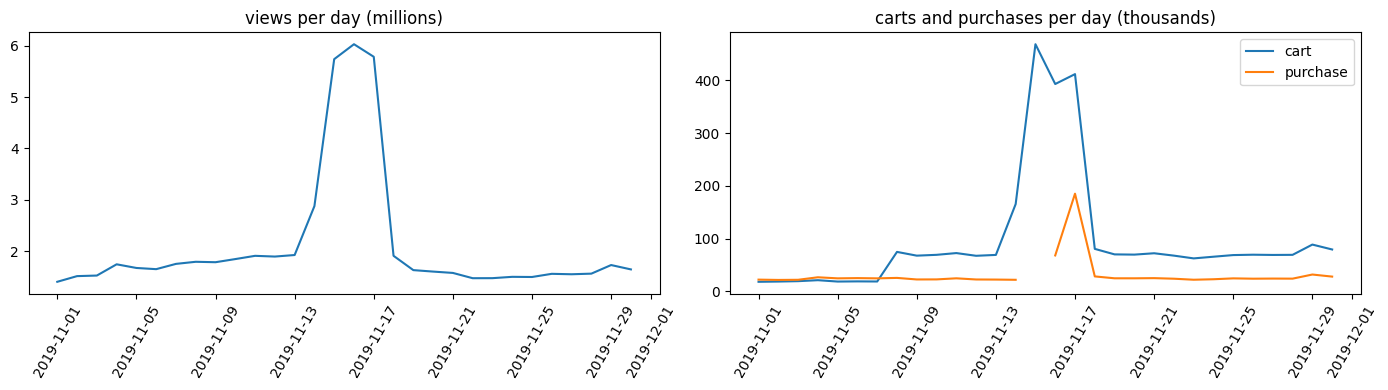

In [0]:
daily = silver.groupBy("event_date").pivot("event_type", EVENT_TYPES).count().orderBy("event_date").toPandas()
S["daily"] = daily.astype({"event_date": str}).to_dict(orient="list")
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(daily["event_date"], daily["view"] / 1e6); ax[0].set_title("views per day (millions)")
ax[1].plot(daily["event_date"], daily["cart"] / 1e3, label="cart"); ax[1].plot(daily["event_date"], daily["purchase"] / 1e3, label="purchase")
ax[1].set_title("carts and purchases per day (thousands)"); ax[1].legend()
for a in ax: a.tick_params(axis="x", rotation=60)
plt.tight_layout(); display(fig)

## 3. Missing values

In [0]:
n = pop["events"]
miss = silver.select([F.sum(F.col(c).isNull().cast("int")).alias(c) for c in COLS]).first().asDict()
S["missing_share"] = {c: miss[c] / n for c in COLS}
display(spark.createDataFrame([(c, miss[c], miss[c] / n) for c in COLS], "column string, nulls long, share double"))

column,nulls,share
event_time,0,0.0
event_type,0,0.0
product_id,0,0.0
category_id,0,0.0
category_code,21871420,0.3244947994442256
brand,9209175,0.136631704510808
price,0,0.0
user_id,0,0.0
user_session,0,0.0


## 4. Price distribution and outliers

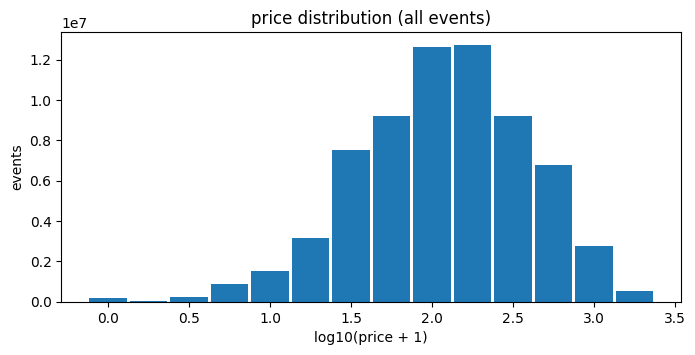

{'0.0': 0.0, '0.01': 5.78, '0.25': 69.24, '0.5': 165.77, '0.75': 360.37, '0.99': 1661.12, '0.999': 2570.18, '1.0': 2574.07} zero-price rows: 187987


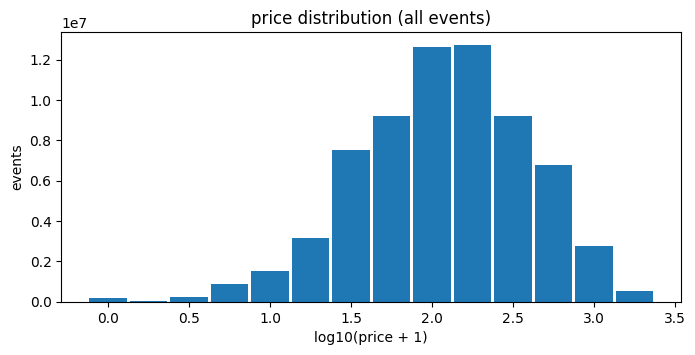

In [0]:
qs = [0.0, 0.01, 0.25, 0.5, 0.75, 0.99, 0.999, 1.0]
pq_ = silver.approxQuantile("price", qs, 0.0001)
S["price_quantiles"] = dict(zip(map(str, qs), pq_))
S["price_zero_rows"] = silver.filter("price = 0").count()
hist = (silver.withColumn("bucket", F.floor(F.log10(F.col("price") + 1) * 4) / 4)
              .groupBy("bucket").count().orderBy("bucket").toPandas())
fig, ax = plt.subplots(figsize=(8, 3.5)); ax.bar(hist["bucket"], hist["count"], width=0.23)
ax.set_xlabel("log10(price + 1)"); ax.set_ylabel("events"); ax.set_title("price distribution (all events)")
display(fig); print(S["price_quantiles"], "zero-price rows:", S["price_zero_rows"])

## 5. Activity skew (possible bots)

In [0]:
per_user = silver.groupBy("user_id").agg(F.count(F.lit(1)).alias("events"))
uq = per_user.approxQuantile("events", [0.5, 0.9, 0.99, 0.9999, 1.0], 0.0001)
S["events_per_user_quantiles"] = dict(zip(["p50", "p90", "p99", "p99.99", "max"], uq))
top = per_user.orderBy(F.desc("events")).limit(10).toPandas()
S["top_users_events"] = top["events"].tolist()
S["share_of_events_top_0_1pct_users"] = (per_user.orderBy(F.desc("events"))
    .limit(max(int(pop["users"] * 0.001), 1)).agg(F.sum("events")).first()[0]) / n
print(json.dumps({k: S[k] for k in ["events_per_user_quantiles", "top_users_events", "share_of_events_top_0_1pct_users"]}, indent=2))

{
  "events_per_user_quantiles": {
    "p50": 5.0,
    "p90": 45.0,
    "p99": 189.0,
    "p99.99": 22925.0,
    "max": 22925.0
  },
  "top_users_events": [
    22925,
    14810,
    6171,
    6111,
    6042,
    4771,
    4256,
    4128,
    3724,
    3686
  ],
  "share_of_events_top_0_1pct_users": 0.03936066657319687
}


## 6. Target: cart -> purchase in the same session

{
  "rows": 2053770,
  "positives": 713140,
  "positive_rate": 0.3472345978371483,
  "purchase_pairs_without_prior_cart": 144744,
  "purchase_pairs": 857884
}


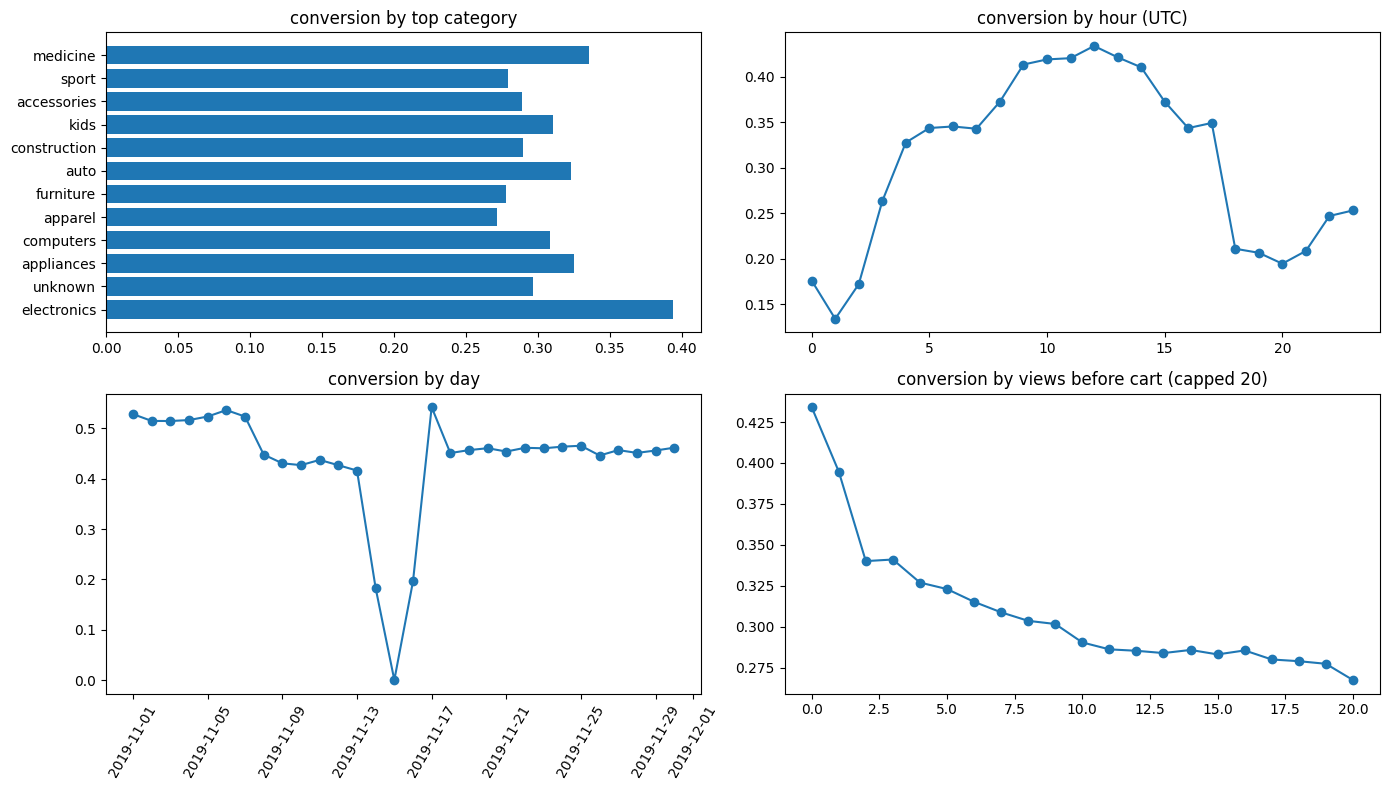

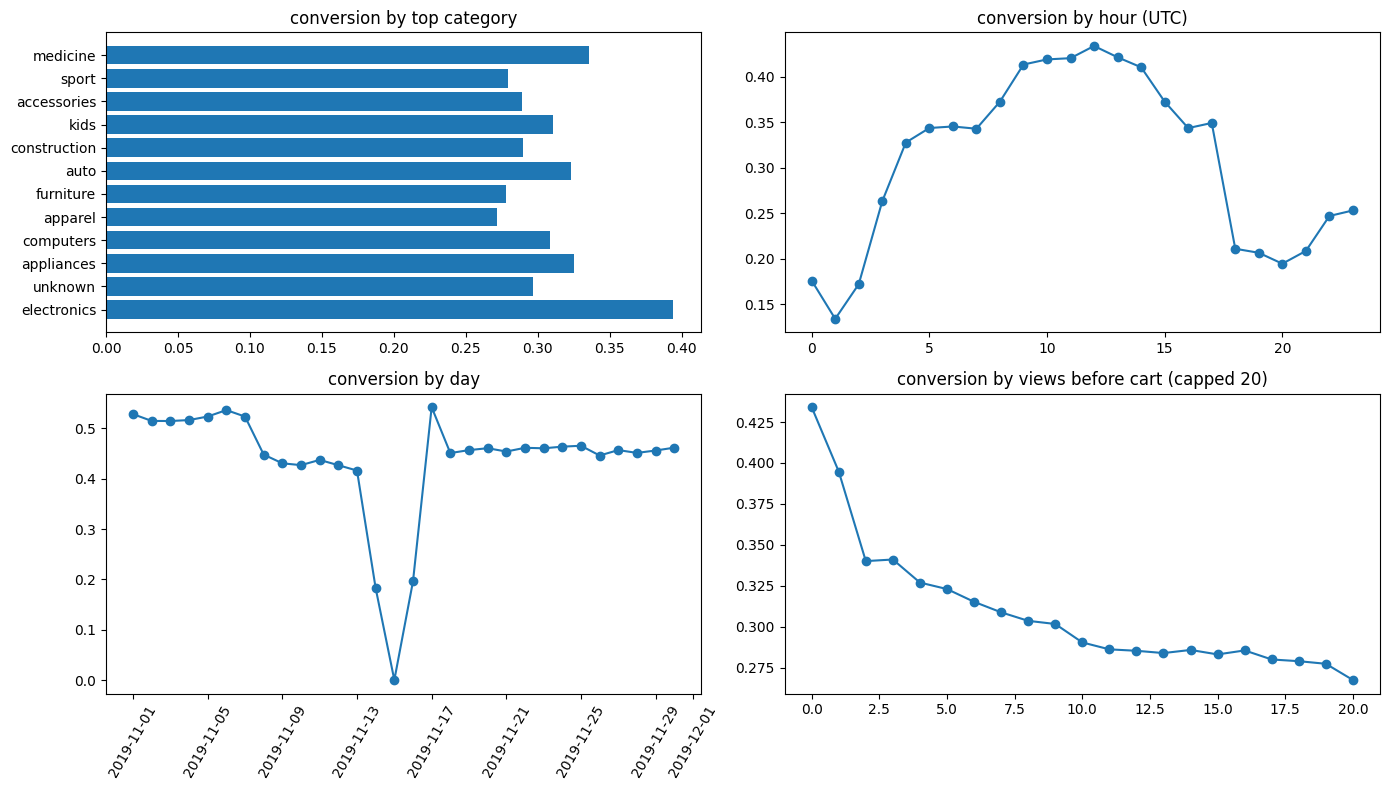

In [0]:
nf = feat.count()
pos = feat.filter("purchased = 1").count()
S["target"] = {"rows": nf, "positives": pos, "positive_rate": pos / nf,
               "purchase_pairs_without_prior_cart": latest["purchase_pairs_without_prior_cart"],
               "purchase_pairs": latest["purchase_pairs"]}
print(json.dumps(S["target"], indent=2))

def rate_by(col, top=None):
    d = feat.groupBy(col).agg(F.count(F.lit(1)).alias("rows"), F.avg("purchased").alias("conv_rate"))
    d = d.orderBy(F.desc("rows")).limit(top) if top else d.orderBy(d.columns[0])
    return d.toPandas()

cat = rate_by("category_l1", 12); hr = rate_by("hour_utc"); day = rate_by("cart_date")
vb = rate_by(F.least(F.col("session_views_before"), F.lit(20)).alias("views_before_capped_20"))
S["conv_by_category"] = cat.to_dict(orient="list"); S["conv_by_hour_utc"] = hr.to_dict(orient="list")
S["conv_by_day"] = day.astype({"cart_date": str}).to_dict(orient="list"); S["conv_by_views_before"] = vb.to_dict(orient="list")
fig, ax = plt.subplots(2, 2, figsize=(14, 8))
ax[0, 0].barh(cat["category_l1"], cat["conv_rate"]); ax[0, 0].set_title("conversion by top category")
ax[0, 1].plot(hr["hour_utc"], hr["conv_rate"], marker="o"); ax[0, 1].set_title("conversion by hour (UTC)")
ax[1, 0].plot(day["cart_date"], day["conv_rate"], marker="o"); ax[1, 0].set_title("conversion by day"); ax[1, 0].tick_params(axis="x", rotation=60)
ax[1, 1].plot(vb["views_before_capped_20"], vb["conv_rate"], marker="o"); ax[1, 1].set_title("conversion by views before cart (capped 20)")
plt.tight_layout(); display(fig)

## 7. Correlation of numeric features with the target (full feature table, one pass)

In [0]:
num = [c for c, t in feat.dtypes if t in ("double", "bigint", "int", "long") and c not in ("product_id", "user_id", "purchased")]
corr = feat.agg(*[F.corr(F.col(c).cast("double"), F.col("purchased").cast("double")).alias(c) for c in num]).first().asDict()
nulls = feat.agg(*[F.avg(F.col(c).isNull().cast("int")).alias(c) for c in num]).first().asDict()
S["corr_with_target"] = corr; S["feature_null_share"] = nulls
display(spark.createDataFrame([(c, float(corr[c]) if corr[c] is not None else None, float(nulls[c])) for c in num],
                              "feature string, pearson_r_with_purchased double, null_share double").orderBy("feature"))

feature,pearson_r_with_purchased,null_share
brand_known,0.033845593545782676,0.0
hour_utc,-0.001831491619594693,0.0
price,0.02301334224295173,0.0
product_prior_carts,0.10896292744307053,0.0
product_prior_conv_rate,0.02773702239871878,0.03896346718473831
product_prior_purchases,0.11224400776507137,0.0
session_carts_before,-0.008165798971528759,0.0
session_elapsed_sec,-0.0034368072263698153,0.0
session_same_product_views_before,-0.04769518412193576,0.0
session_views_before,-0.05931817320931615,0.0


In [0]:
write_json(uri("curated", "project/eda/eda_summary.json"), S)

Wrote 9835 bytes.
saved abfss://curated@amazonlake60304642.dfs.core.windows.net/project/eda/eda_summary.json


In [0]:
display(spark.sql("DESCRIBE HISTORY dsai3202_databricks.s_60304642.project_silver_events LIMIT 3"))
display(spark.sql("DESCRIBE HISTORY dsai3202_databricks.s_60304642.project_features_v1 LIMIT 3")) #

version,timestamp,userId,userName,operation,operationParameters,job,notebook,queryHistoryStatementId,clusterId,readVersion,isolationLevel,isBlindAppend,operationMetrics,userMetadata,engineInfo
29,2026-11-14T13:20:37Z,147616070259781,60304642@udst.edu.qa,SET TBLPROPERTIES,"Map(properties -> {""project.source_sha256"":""addd9a27ed99"",""project.last_run_id"":""926454798811512""})","List(831438040589676, dsai3202-project-60304642, 926454798811512, 48168392110218, 147616070259781, manual, 7405613772250173)",List(2825461051145579),null,1114-100955-9kp9o534,28,WriteSerializable,true,Map(),null,Databricks-Runtime/18.x-photon-scala2.13
28,2026-11-14T13:20:36.001Z,147616070259781,60304642@udst.edu.qa,CHANGE COLUMN,"Map(column -> {""name"":""brand_clean"",""type"":""string"",""nullable"":true,""metadata"":{""comment"":""brand, or 'unknown'.""}})","List(831438040589676, dsai3202-project-60304642, 926454798811512, 48168392110218, 147616070259781, manual, 7405613772250173)",List(2825461051145579),null,1114-100955-9kp9o534,27,WriteSerializable,true,Map(),null,Databricks-Runtime/18.x-photon-scala2.13
27,2026-11-14T13:20:36Z,147616070259781,60304642@udst.edu.qa,CHANGE COLUMN,"Map(column -> {""name"":""category_l1"",""type"":""string"",""nullable"":true,""metadata"":{""comment"":""First segment of category_code, or 'unknown'.""}})","List(831438040589676, dsai3202-project-60304642, 926454798811512, 48168392110218, 147616070259781, manual, 7405613772250173)",List(2825461051145579),null,1114-100955-9kp9o534,26,WriteSerializable,true,Map(),null,Databricks-Runtime/18.x-photon-scala2.13


version,timestamp,userId,userName,operation,operationParameters,job,notebook,queryHistoryStatementId,clusterId,readVersion,isolationLevel,isBlindAppend,operationMetrics,userMetadata,engineInfo
5,2026-11-14T13:22:40.001Z,147616070259781,60304642@udst.edu.qa,SET TBLPROPERTIES,"Map(properties -> {""comment"":""Cart-to-purchase features v1. One row per (user_session, product_id) at its first cart event; label purchased.\nAll features use only events strictly before cart_ts. Built from dsai3202_databricks.s_60304642.project_silver_events version 29. See docs/FEATURES.md.""})","List(831438040589676, dsai3202-project-60304642, 926454798811512, 172163016191200, 147616070259781, manual, 7405613772250173)",List(2825461051145576),null,1114-100955-9kp9o534,4,WriteSerializable,true,Map(),null,Databricks-Runtime/18.x-photon-scala2.13
4,2026-11-14T13:22:40Z,147616070259781,60304642@udst.edu.qa,SET TBLPROPERTIES,"Map(properties -> {""project.feature_version"":""1"",""project.silver_version"":""29"",""project.last_run_id"":""926454798811512""})","List(831438040589676, dsai3202-project-60304642, 926454798811512, 172163016191200, 147616070259781, manual, 7405613772250173)",List(2825461051145576),null,1114-100955-9kp9o534,3,WriteSerializable,true,Map(),null,Databricks-Runtime/18.x-photon-scala2.13
3,2026-11-14T13:22:39Z,147616070259781,60304642@udst.edu.qa,WRITE,"Map(mode -> Overwrite, statsOnLoad -> false, partitionBy -> [])","List(831438040589676, dsai3202-project-60304642, 926454798811512, 172163016191200, 147616070259781, manual, 7405613772250173)",List(2825461051145576),null,1114-100955-9kp9o534,2,WriteSerializable,false,"Map(numFiles -> 6, numRemovedFiles -> 9, numRemovedBytes -> 160813560, numDeletionVectorsRemoved -> 0, numOutputRows -> 2053770, numOutputBytes -> 159229897)",null,Databricks-Runtime/18.x-photon-scala2.13
